# EVRP Data Exploration

Load and visualize EVRP benchmark instances.

In [1]:
import math
import sys
from pathlib import Path
import matplotlib.pyplot as plt

from evrp_decoder.loader import load_all
from evrp_decoder._evrp_core import Instance, NodeType

In [2]:
def plot_instance(instance: Instance, ax: plt.Axes | None = None, title: str | None = None) -> plt.Axes:
    """Plot an EVRP instance showing nodes, depot, and charging stations.

    Parameters
    ----------
    instance : Instance
        Parsed EVRP instance (from ``loader.load_evrp``).
    ax : plt.Axes, optional
        Matplotlib axes to plot on. Creates a new figure if None.

    Returns
    -------
    plt.Axes
        The axes with the plotted instance.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))

    depot_x, depot_y = [], []
    cust_x, cust_y = [], []
    cs_x, cs_y = [], []

    for i in range(instance.node_cnt()):
        node = instance.node(i)
        if node.type == NodeType.Depot:
            depot_x.append(node.x)
            depot_y.append(node.y)
        elif node.type == NodeType.Customer:
            cust_x.append(node.x)
            cust_y.append(node.y)
        elif node.type == NodeType.ChargingStation:
            cs_x.append(node.x)
            cs_y.append(node.y)

    ax.scatter(cust_x, cust_y, c="steelblue", marker="o", s=5,
               label=f"Customers ({len(cust_x)})", zorder=2)
    ax.scatter(cs_x, cs_y, c="forestgreen", marker="^", s=70,
               label=f"Charging stations ({len(cs_x)})", zorder=3)
    ax.scatter(depot_x, depot_y, c="crimson", marker="s", s=100,
               label="Depot", zorder=4)

    ax.set_title(title if title else instance.name, fontsize=13, fontweight="bold")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(fontsize=9, loc="best")
    ax.grid(True, alpha=0.3)
    ax.set_aspect("equal", adjustable="datalim")

    return ax

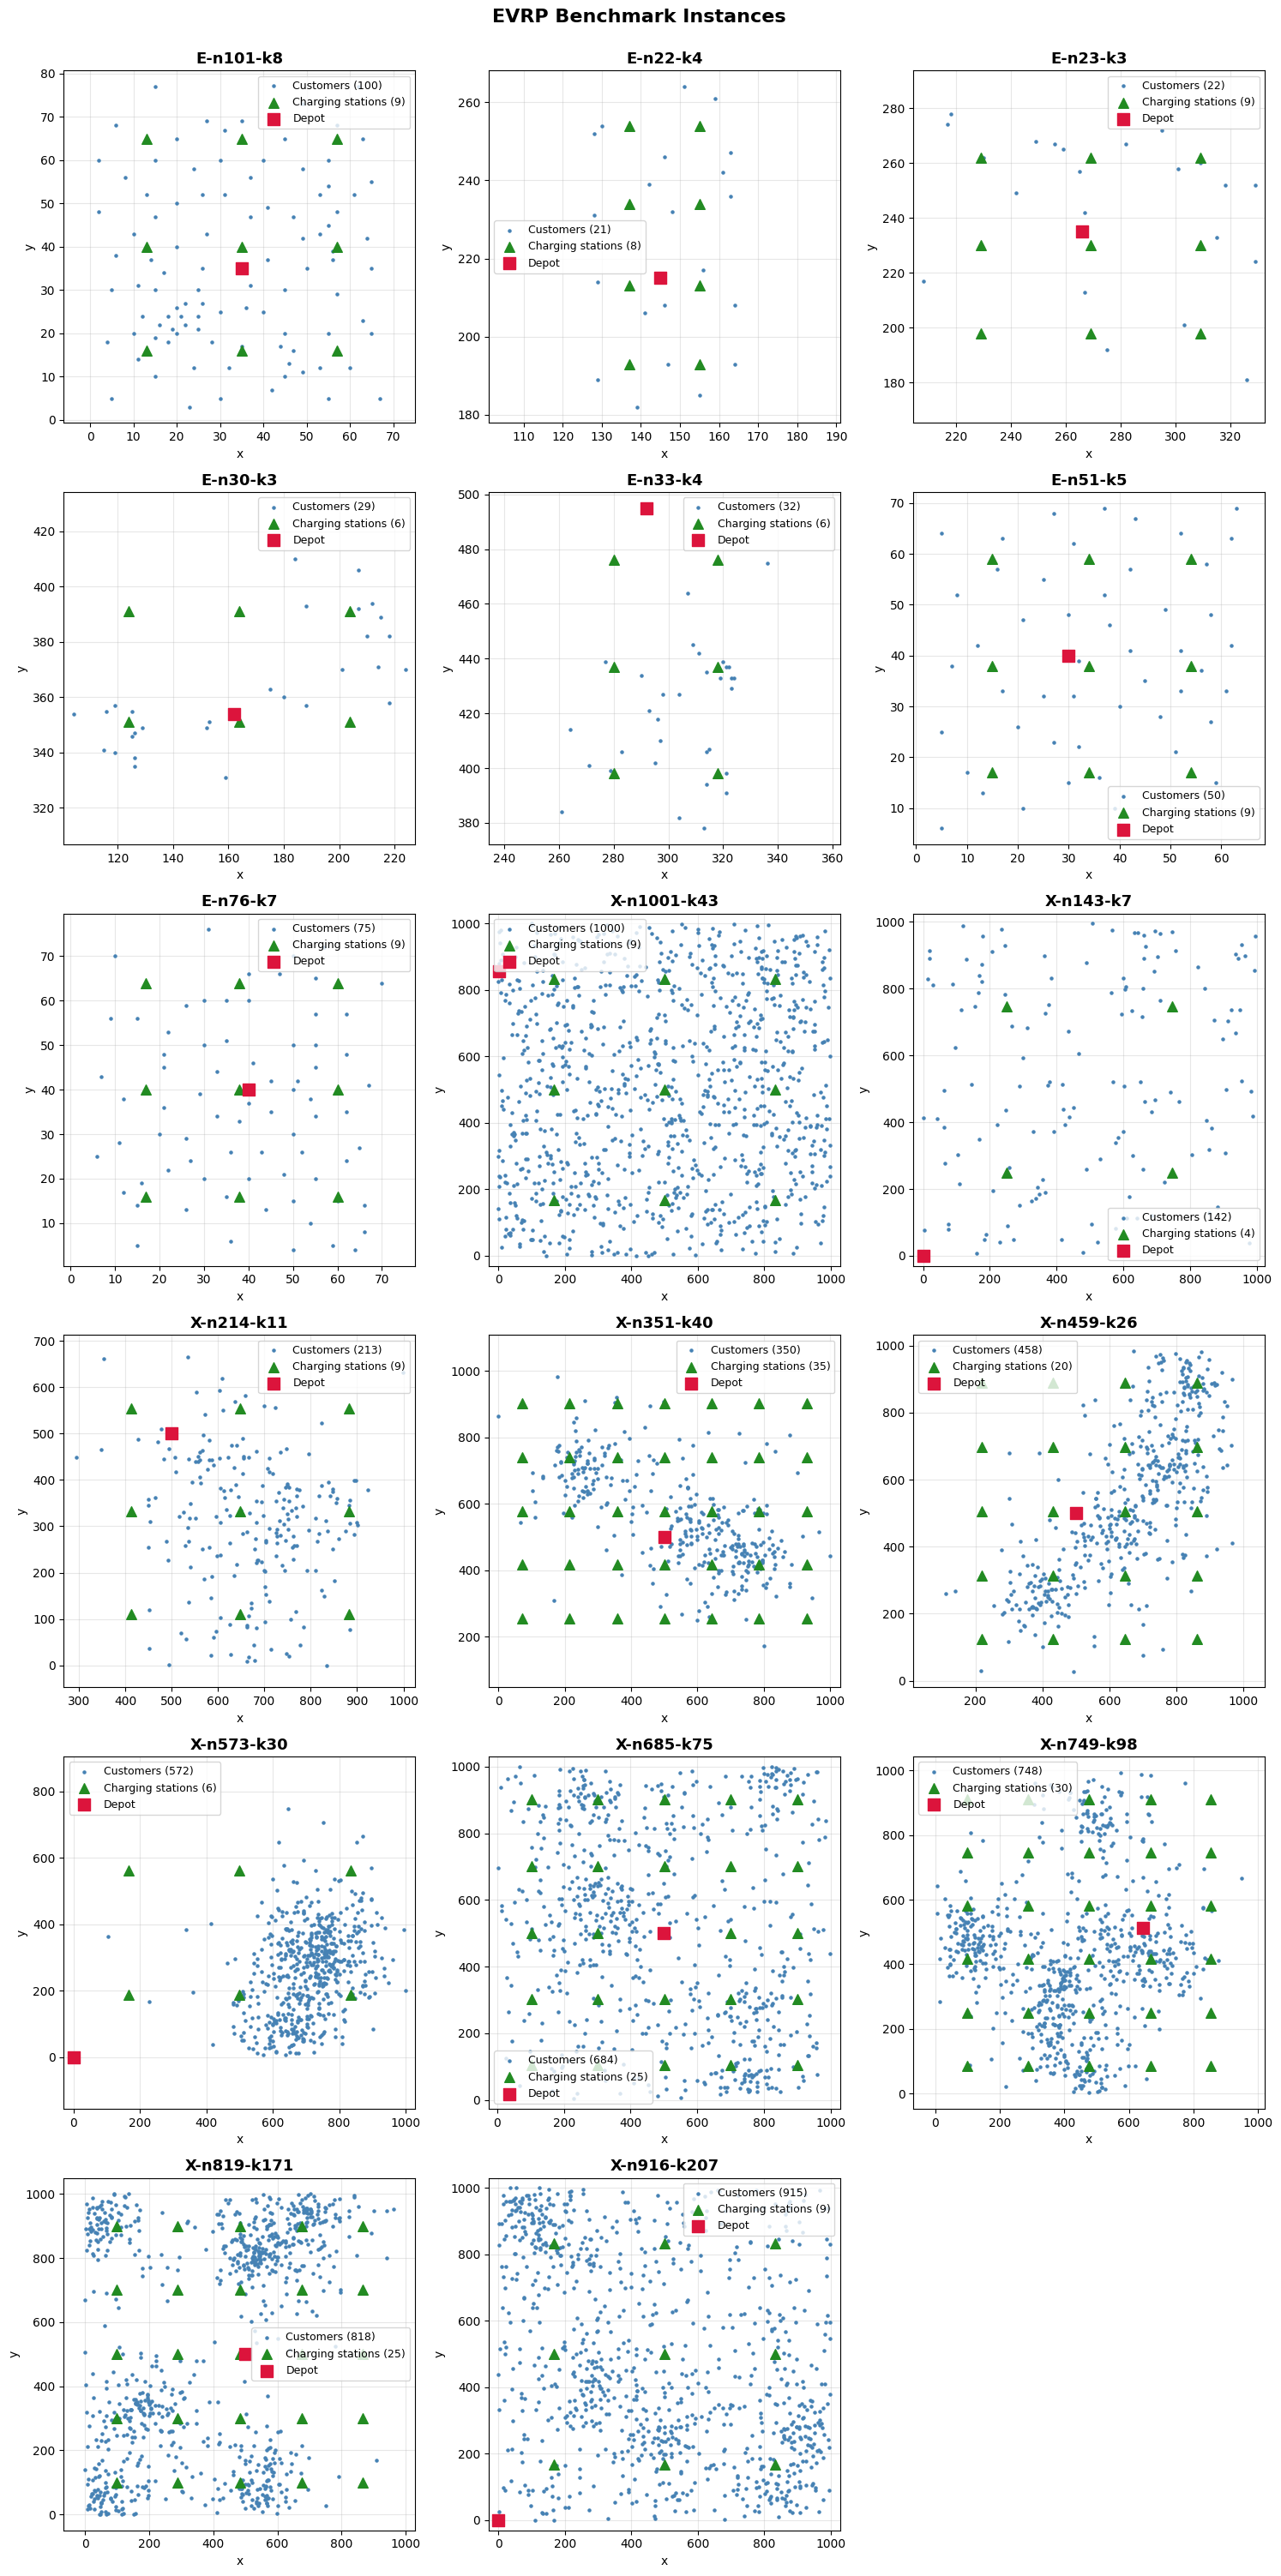

In [3]:
dataset_dir = "../dataset"
instances = load_all(dataset_dir)

n = len(instances)
cols = 3
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
axes_flat = axes.flatten()

for i, (name, inst) in enumerate(sorted(instances.items())):
    plot_instance(inst, ax=axes_flat[i], title=name)

# Hide unused subplots
for j in range(n, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle("EVRP Benchmark Instances", fontsize=16, fontweight="bold", y=1.0)
fig.tight_layout()